# Piloto STONE v4 — primeiro experimento: onde está a baixa entropia?

**Pergunta:** nas posições em que o STONE decide aplicar a marca durante a geração da função,
qual é a distribuição da entropia antes desse viés? Quantas posições um filtro adicional removeria?

Este notebook é uma evolução didática da v3. A análise principal usa **somente a função pedida**;
as saídas completas aparecem como comparação. Separa **elegibilidade na geração** de
**contagem no detector**, mostra resultados por problema e exporta tabelas, figuras e um relatório.

## Como rodar no Colab
1. Envie este `.ipynb` ao Colab. Para **gerar amostras**, escolha **Ambiente de execução → Alterar tipo → T4 GPU**.
2. Edite apenas a célula **Configuração**, abaixo, e execute as células em ordem.
3. No modo `auto`, se o JSON da v3 e seu `_meta.json` existirem, eles serão **reanalisados**, sem carregar
   os pesos do modelo. Se não existirem, será iniciada uma rodada v4. A escolha aparece antes de qualquer geração.
4. O Drive guarda cada problema concluído. Uma queda do Colab não perde os problemas já salvos.
5. Para mudar modelo, modo, δ ou semente, reexecute desde a configuração. Para mudar só os limiares,
   reexecute desde **Construir as duas populações**. Não é preciso gerar novamente.

**Reanálise não precisa de GPU**, mas precisa de internet na primeira vez para baixar o tokenizer e o conjunto com os prompts.
Os arquivos v3 esperados estão em `MyDrive/stone_pilot/`. Não se extraem resultados numéricos das
saídas impressas no notebook antigo: precisamos do JSON que a v3 salvou no Drive.

### O que H quer dizer?
H é a entropia **da distribuição do próximo token em uma posição**, em *nats* (logaritmo natural).
Uma opção dominante → H baixo. Várias alternativas competitivas → H maior.
H não mede se o código está correto. Média soma e divide; mediana é o valor central.
Uma cauda com poucos valores altos pode elevar a média mesmo com mediana próxima de zero.

| Exemplo didático (não são resultados do piloto) | H em nats |
|---|---:|
| Duas opções com probabilidades 99% e 1% | 0,056 |
| Duas opções com probabilidades 50% e 50% | 0,693 |
| Cinco opções com probabilidades 20% cada | 1,609 |

Não existe uma fronteira universal entre alta e baixa entropia. `H > 0,9` é um **limiar de seleção**
do experimento: até o exemplo 50%/50% seria descartado por ele. Para interpretar a cauda,
considere `0,01; 0,02; 0,03; 0,04; 0,08; 0,08; 0,10; 0,20; 2,00; 4,00`:
a mediana é 0,08, mas a média é 0,656 porque os dois valores altos a elevam.

### Limite deste primeiro experimento
Medimos quanto o filtro mudaria a seleção de posições. **Não implementamos ainda a geração híbrida
STONE + entropia nem medimos pass@1.** As análises opcionais de detecção mudam só o detector.


## 1. Configuração

Comece com os padrões. Para testar a instalação rapidamente, use `N_PROBLEMS = 2` e
`MAX_NEW = 40` no modo `novo`; essa configuração gera arquivos próprios.

`paper` e `repo` preservam as duas interpretações operacionais da v3, **não são certificações
de reprodução oficial**. O modo `paper` usa um candidato amostrado para decidir a elegibilidade,
uma regra sintática ampla e hash do token anterior. `repo` usa argmax, regra exata, lista fixa e
vocabulário verde limitado. A permutação é gerada na CPU, como na v3; não reproduz a lista GPU oficial.


In [ ]:
MODO_EXECUCAO = 'auto'       # 'auto', 'novo' ou 'reanalisar_v3'
USAR_DRIVE = True           # False: arquivos temporários em /content/stone_pilot
ARQUIVO_V3 = ''             # vazio: procurar o nome padrão no OUT_DIR

MODE = 'paper'             # 'paper' ou 'repo'; usado SOMENTE em rodada nova
MODEL_ID = None            # None: Qwen2.5-Coder-3B (paper) / 3B-Instruct (repo)
MODEL_REVISION = 'main'    # commit exato recomendado para reproduções futuras
QUANT_4BIT = False         # 3B FP16 é o padrão; 7B na T4: True
GAMMA = 0.5
DELTA = 0.5
HASH_KEY = 15485863
MAX_NEW = 200
MIN_LEN = 200              # apenas modo repo; comprimento TOTAL, como na v3
N_PROBLEMS = 50            # primeiros N, sem aleatorizar; não é amostra aleatória do benchmark
SEED = 0
TAUS = [0.3, 0.6, 0.9, 1.2]
LIMIAR_REFERENCIA = 0.9     # definido antes de analisar; não escolher pelo melhor resultado
BOOTSTRAP_B = 2000
N_PREVIAS = 5
CALCULAR_DETECCAO = False  # extra: AUROC; exige negativos (v3 já pode contê-los)
GERAR_NEGATIVOS = False    # rodada nova: gera sem marca e pontua solução de referência

assert MODO_EXECUCAO in {'auto', 'novo', 'reanalisar_v3'}
assert MODE in {'paper', 'repo'}
assert 0 < GAMMA < 1 and DELTA >= 0
assert N_PROBLEMS > 0 and MAX_NEW > 0 and BOOTSTRAP_B > 0
assert TAUS and all(t >= 0 for t in TAUS)
assert LIMIAR_REFERENCIA in TAUS


## 2. Instalação enxuta

Fixamos a versão de Transformers para não mudar silenciosamente de API. Não reinstalamos
PyTorch/CUDA, NumPy nem protobuf do Colab. Não instalamos EvalPlus: o conjunto público é lido
diretamente da release oficial. Isso evita o conflito de protobuf visto na v3.

Execute preferencialmente numa sessão nova. Se Transformers já foi importado em outra versão,
a célula explica como reiniciar o ambiente antes de continuar.


In [ ]:
import sys, subprocess, importlib.util, importlib.metadata
from packaging.requirements import Requirement

TF_VERSION = '4.57.1'
loaded = sys.modules.get('transformers')
if loaded is not None and loaded.__version__ != TF_VERSION:
    raise RuntimeError('Transformers já foi importado em outra versão. Reinicie o ambiente e rode do início.')
requirements = []
try:
    if importlib.metadata.version('transformers') != TF_VERSION:
        requirements.append(f'transformers=={TF_VERSION}')
except importlib.metadata.PackageNotFoundError:
    requirements.append(f'transformers=={TF_VERSION}')
for module, package in [('accelerate', 'accelerate>=1.1,<2'), ('pandas', 'pandas'),
                        ('matplotlib', 'matplotlib'), ('scipy', 'scipy'), ('tqdm', 'tqdm')]:
    requirement = Requirement(package)
    try:
        compatible = importlib.metadata.version(requirement.name) in requirement.specifier
    except importlib.metadata.PackageNotFoundError:
        compatible = False
    if importlib.util.find_spec(module) is None or not compatible:
        requirements.append(package)
if QUANT_4BIT:
    requirement = Requirement('bitsandbytes>=0.46,<0.49')
    try:
        compatible = importlib.metadata.version('bitsandbytes') in requirement.specifier
    except importlib.metadata.PackageNotFoundError:
        compatible = False
    if not compatible:
        requirements.append(str(requirement))
if requirements:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *requirements])
print('Dependências prontas. PyTorch e a pilha científica existente foram preservados.')


Dependências prontas. PyTorch e a pilha científica existente foram preservados.


## 3. Arquivos, retomada e procedência

Uma reanálise usa a configuração **do arquivo salvo**, não a que estiver digitada acima.
Ela não mistura amostras antigas com gerações novas. Para continuar uma geração interrompida,
use `novo`: a v4 só retoma um arquivo cuja configuração e ambiente registrados coincidam.


In [ ]:
import os, json, math, random, hashlib, functools, collections, time, gc, gzip, io, tokenize, token, ast, re
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

if USAR_DRIVE:
    try:
        from google.colab import drive
    except ImportError as exc:
        raise RuntimeError('Drive requer Colab. Fora do Colab, configure USAR_DRIVE=False.') from exc
    drive.mount('/content/drive')
    OUT_DIR = Path('/content/drive/MyDrive/stone_pilot')
else:
    OUT_DIR = Path('/content/stone_pilot') if Path('/content').exists() else Path.cwd() / 'stone_pilot'
OUT_DIR.mkdir(parents=True, exist_ok=True)

def atomic_json(path, obj):
    path = Path(path)
    tmp = path.with_name(path.name + '.tmp')
    tmp.write_text(json.dumps(obj, ensure_ascii=False, allow_nan=False), encoding='utf-8')
    os.replace(tmp, path)

default_model = 'Qwen/Qwen2.5-Coder-3B' + ('-Instruct' if MODE == 'repo' else '')
requested_model = MODEL_ID or default_model
legacy = Path(ARQUIVO_V3) if ARQUIVO_V3 else OUT_DIR / f'he_plus_{MODE}_{requested_model.split("/")[-1]}_d{DELTA}.json'
legacy_meta = legacy.with_name(legacy.stem + '_meta.json')
USE_LEGACY = MODO_EXECUCAO == 'reanalisar_v3' or (MODO_EXECUCAO == 'auto' and legacy.exists())
legacy_records = None
if USE_LEGACY:
    if not legacy.exists() or not legacy_meta.exists():
        raise FileNotFoundError(f'Reanálise precisa de ambos: {legacy} e {legacy_meta}. Corrija ARQUIVO_V3 ou use novo.')
    old_meta = json.loads(legacy_meta.read_text(encoding='utf-8'))
    required = {'MODEL_ID', 'MODE', 'CFG', 'GV', 'GAMMA', 'DELTA', 'HASH_KEY', 'GEN_KW', 'MAX_NEW'}
    missing = required - set(old_meta)
    if missing:
        raise ValueError(f'Metadados v3 incompletos: {sorted(missing)}. Não será inferida uma configuração.')
    MODEL_ID, MODE = old_meta['MODEL_ID'], old_meta['MODE']
    CFG, GV = old_meta['CFG'], int(old_meta['GV'])
    GAMMA, DELTA, HASH_KEY = old_meta['GAMMA'], old_meta['DELTA'], old_meta['HASH_KEY']
    MAX_NEW = old_meta['MAX_NEW']
    legacy_records = json.loads(legacy.read_text(encoding='utf-8'))
    if not isinstance(legacy_records, list) or not legacy_records:
        raise ValueError('O JSON v3 deve conter uma lista não vazia de problemas.')
    print(f'REANÁLISE V3: {legacy}\n{len(legacy_records)} problemas disponíveis; usar até {N_PROBLEMS}.')
    print('Não será carregado o modelo nem serão acrescentadas gerações a esse arquivo.')
else:
    MODEL_ID = requested_model
    CFG = dict(PREFIX=1 if MODE == 'paper' else 0,
               ELIG='sampled' if MODE == 'paper' else 'argmax', SYN='broad' if MODE == 'paper' else 'exact')
    print('RODADA NOVA/RETOMADA V4. Será necessário GPU e baixar os pesos do modelo.')
print('Modelo:', MODEL_ID, '| modo:', MODE, '| δ:', DELTA, '| configuração:', CFG)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
RODADA NOVA/RETOMADA V4. Será necessário GPU e baixar os pesos do modelo.
Modelo: Qwen/Qwen2.5-Coder-3B | modo: paper | δ: 0.5 | configuração: {'PREFIX': 1, 'ELIG': 'sampled', 'SYN': 'broad'}


## 4. Tokenizer e modelo (pesos carregados apenas se necessário)

Usamos geração causal de continuação do prompt do HumanEval, sem template de conversa.
O tokenizer usa a mesma revisão dos pesos nas rodadas novas. Na v3 não foi salvo o commit
do tokenizer: a reanálise registra essa limitação e confere o alinhamento dos tokens disponíveis.


In [ ]:
import transformers
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig, LogitsProcessor, LogitsProcessorList, GenerationConfig

# Ao reexecutar desde a configuração, libera pesos eventualmente carregados na rodada anterior.
if 'model' in globals():
    del model
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
tok = AutoTokenizer.from_pretrained(MODEL_ID, revision=MODEL_REVISION)
if tok.pad_token_id is None:
    tok.pad_token = tok.eos_token
model = None
GEN_KW = dict(old_meta['GEN_KW']) if USE_LEGACY else None
if not USE_LEGACY:
    if not torch.cuda.is_available():
        raise RuntimeError('Para gerar: Ambiente de execução → Alterar tipo → T4 GPU. Reanálise v3 pode usar CPU.')
    free_gb = torch.cuda.mem_get_info()[0] / 1e9
    print('GPU:', torch.cuda.get_device_name(0), '| memória livre:', round(free_gb, 2), 'GB')
    if not QUANT_4BIT and free_gb < 9:
        raise RuntimeError('Pouca VRAM livre para o padrão 3B FP16. Reinicie a sessão ou use QUANT_4BIT=True.')
    kwargs = dict(revision=MODEL_REVISION, device_map={'': 0}, dtype=torch.float16,
                  attn_implementation='sdpa', low_cpu_mem_usage=True)
    if QUANT_4BIT:
        kwargs['quantization_config'] = BitsAndBytesConfig(
            load_in_4bit=True, bnb_4bit_quant_type='nf4', bnb_4bit_compute_dtype=torch.float16,
            bnb_4bit_use_double_quant=True)
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, **kwargs).eval()
    V = model.get_output_embeddings().weight.shape[0]
    GV = min(50272, V) if MODE == 'repo' else V
    GEN_KW = dict(do_sample=True, max_new_tokens=MAX_NEW, pad_token_id=tok.pad_token_id,
                  eos_token_id=tok.eos_token_id, use_cache=True, num_beams=1)
    if MODE == 'paper':
        GEN_KW.update(temperature=1.0, top_k=50, top_p=1.0, repetition_penalty=1.0)
        # Configuração explícita: não herdar warpers/processadores ocultos de generation_config.
        generation_config = GenerationConfig(**GEN_KW)
    else:
        GEN_KW.update(min_length=MIN_LEN, no_repeat_ngram_size=4)
        generation_config = GenerationConfig.from_dict(model.generation_config.to_dict())
        generation_config.update(**GEN_KW)
    print('Amostragem:', {k: getattr(generation_config, k) for k in
                         ['temperature', 'top_k', 'top_p', 'repetition_penalty', 'no_repeat_ngram_size']})
    print('Vocabulário dos logits:', V, '| vocabulário verde:', GV)
else:
    print('Tokenizer pronto. Pesos do modelo dispensados nesta reanálise.')


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

GPU: Tesla T4 | memória livre: 15.53 GB


... (4 outputs left out)

model-00001-of-00002.safetensors:   0%|          | 0.00/4.96G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/139 [00:00<?, ?B/s]

Amostragem: {'temperature': 1.0, 'top_k': 50, 'top_p': 1.0, 'repetition_penalty': 1.0, 'no_repeat_ngram_size': 0}
Vocabulário dos logits: 151936 | vocabulário verde: 151936


## 5. Regras da marca e entropia

A marca soma δ aos logits da lista verde quando a posição é elegível. O gerador **não usa H
para decidir a elegibilidade** neste experimento; o filtro será simulado na análise.

$$H=-\sum_v p(v)\ln p(v)$$

Registramos H antes do nosso viés e antes de temperatura/top-k/top-p. No `paper`, corresponde
à distribuição completa dos logits do modelo. No `repo`, outros processadores de `generate`
(como bloqueio de n-gramas) já podem ter atuado: os dois modos não devem ser agrupados.
O candidato que decide a elegibilidade e o token final são amostragens distintas, como na v3.


In [ ]:
KEYWORDS = """True False None and as assert async await break class continue def del elif else
except finally for from global if import in is lambda nonlocal not or pass raise return try while
with yield""".split()
OPS = ['+', '-', '*', '/', '%', '**', '//', '=', '==', '!=', '>', '<', '>=', '<=', '+=', '-=',
       '*=', '/=', '%=', '//=', '**=', '&', '|', '<<', '>>', '^', '~']
DELIMS = ['(', ')', '[', ']', '{', '}', ',', ':', '.', ';', '@', '->', '...']
SYN_SET = set(KEYWORDS + OPS + DELIMS + [' ', '\t', '\n'] + 'int float complex str bytes bool list tuple set dict NoneType'.split())
PUNCT_CHARS = set('()[]{},:.;@->=+*/%<>!&|^~')

@functools.lru_cache(maxsize=32768)
def is_syn(tid):
    d = tok.decode([int(tid)], skip_special_tokens=True, clean_up_tokenization_spaces=False)
    st = d.strip()
    if CFG['SYN'] == 'exact':
        return d in SYN_SET or st in SYN_SET
    return st == '' or st in SYN_SET or all(c in PUNCT_CHARS for c in st)

def seed_key(prev_ids):
    return 1 if CFG['PREFIX'] == 0 else int(prev_ids[-1]) % GV

@functools.lru_cache(maxsize=128)  # evita o cache de ~1 GB que 8192 máscaras poderia produzir
def green_mask_cpu(key, gv, gamma, hash_key):
    generator = torch.Generator(device='cpu').manual_seed(int(hash_key * key))
    mask = torch.zeros(gv, dtype=torch.bool)
    mask[torch.randperm(gv, generator=generator)[:int(gv * gamma)]] = True
    return mask

def is_green(key, tid):
    return 0 <= tid < GV and bool(green_mask_cpu(key, GV, GAMMA, HASH_KEY)[tid])

def entropy_rows(logits):
    logp = torch.log_softmax(logits.float(), dim=-1)
    p = logp.exp()
    return -torch.where(p > 0, p * logp, torch.zeros_like(p)).sum(-1)

class StoneProc(LogitsProcessor):
    def __init__(self):
        self.recs = []
    def __call__(self, input_ids, scores):
        if scores.shape[0] != 1:
            raise ValueError('Este piloto registra uma sequência por vez (batch=1, num_beams=1).')
        H = float(entropy_rows(scores[0]).item())
        if CFG['ELIG'] == 'argmax':
            probe = int(scores[0].argmax().item())
        else:
            vals, idx = torch.topk(scores[0].float(), min(50, scores.shape[-1]))
            probe = int(idx[torch.multinomial(torch.softmax(vals, -1), 1)].item())
        eligible = not is_syn(probe)
        key = seed_key(input_ids[0].tolist())
        self.recs.append(dict(H=H, eligible=eligible, probe_id=probe))
        if eligible:
            mask = green_mask_cpu(key, GV, GAMMA, HASH_KEY).to(scores.device)
            scores = scores.clone()
            scores[0, :GV] += mask.to(scores.dtype) * DELTA
        return scores

def seed_for(task_id, branch):
    # Reprodutível por problema/ramo: retomar não reinicia a sequência aleatória de outro problema.
    payload = f'{SEED}|{task_id}|{branch}'.encode()
    return int.from_bytes(hashlib.sha256(payload).digest()[:4], 'little')

@torch.inference_mode()
def generate(prompt, task_id, watermark=True):
    s = seed_for(task_id, 'wm' if watermark else 'unwm')
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    enc = tok(prompt, return_tensors='pt', add_special_tokens=False,
              return_token_type_ids=False).to(model.device)
    proc = StoneProc() if watermark else None
    out = model.generate(**enc, generation_config=generation_config,
                         logits_processor=LogitsProcessorList([proc]) if proc else None)
    ids, plen = out[0].tolist(), enc.input_ids.shape[1]
    return ids, plen, proc.recs if proc else None

def rows_from_generation(ids, plen, recs):
    if len(ids) - plen != len(recs):
        raise ValueError('Desalinhamento entre registros da geração e tokens. Não analisar silenciosamente.')
    return [(float(rec['H']), is_green(seed_key(ids[:i]), int(tid)), is_syn(tid), True, int(tid))
            for i, (tid, rec) in enumerate(zip(ids[plen:], recs), start=plen)]

@torch.inference_mode()
def score_completion(prompt_ids, completion_ids):
    # Teacher forcing incremental: evita materializar [comprimento, vocabulário] na GPU.
    if not completion_ids:
        return []
    all_ids = list(prompt_ids)
    inputs = torch.tensor([all_ids], device=model.device)
    out = model(inputs, use_cache=True, logits_to_keep=1)
    rows = []
    for j, tid in enumerate(completion_ids):
        H = float(entropy_rows(out.logits[0, -1]).item())
        rows.append((H, is_green(seed_key(all_ids), int(tid)), is_syn(tid), True, int(tid)))
        all_ids.append(int(tid))
        if j + 1 < len(completion_ids):
            out = model(torch.tensor([[tid]], device=model.device), past_key_values=out.past_key_values,
                        use_cache=True, logits_to_keep=1)
    return rows


## 6. Obter as amostras

Na reanálise, lemos os resultados locais do Drive e obtemos os prompts da release pública caso
não estejam no cache. Na geração nova, baixamos o HumanEval+ v0.1.10 da release oficial,
mas **não executamos o código gerado nem os testes**.
O checkpoint é salvo após cada problema; uma interrupção durante um problema faz refazer apenas esse problema.

A identidade da rodada inclui ambiente, configuração, versão do algoritmo, revisão resolvida do modelo
e do tokenizer. N_PROBLEMS e os limiares são parâmetros de análise: ampliar N na mesma rodada reaproveita o prefixo.


In [ ]:
from urllib.request import Request, urlopen
from tqdm.auto import tqdm

DATASET_URL = 'https://github.com/evalplus/humanevalplus_release/releases/download/v0.1.10/HumanEvalPlus.jsonl.gz'

def download_dataset():
    cache = OUT_DIR / 'HumanEvalPlus_v0.1.10.jsonl.gz'
    if not cache.exists():
        last = None
        for attempt in range(3):
            try:
                with urlopen(Request(DATASET_URL, headers={'User-Agent': 'stone-entropy-pilot/4'}), timeout=90) as response:
                    payload = response.read()
                gzip.decompress(payload)  # validar antes de gravar
                tmp = cache.with_suffix('.tmp')
                tmp.write_bytes(payload)
                os.replace(tmp, cache)
                break
            except Exception as exc:
                last = exc
                print(f'Tentativa {attempt + 1}/3 de baixar o conjunto falhou: {type(exc).__name__}')
                time.sleep(2)
        else:
            raise RuntimeError('Não foi possível baixar o HumanEval+. Verifique a conexão e reexecute esta célula.') from last
    payload = cache.read_bytes()
    records = [json.loads(line) for line in gzip.decompress(payload).decode('utf-8').splitlines() if line.strip()]
    probs = {r['task_id']: r for r in records}
    return probs, hashlib.sha256(payload).hexdigest()

if USE_LEGACY:
    all_results = legacy_records
    run_meta = dict(source='v3', source_file=str(legacy), original_meta=old_meta,
                    tokenizer_revision_requested=MODEL_REVISION,
                    tokenizer_commit=getattr(tok, '_commit_hash', None) or tok.init_kwargs.get('_commit_hash'),
                    caveat='v3 não salvou commits/ambiente; não se certifica equivalência exata do tokenizer atual.')
    RUN_ID = 'v3_' + hashlib.sha256(legacy.read_bytes()).hexdigest()[:12]
else:
    probs, dataset_sha = download_dataset()
    task_order = sorted(probs, key=lambda tid: int(tid.split('/')[-1]))
    if N_PROBLEMS > len(task_order):
        raise ValueError(f'O conjunto contém {len(task_order)} problemas; reduza N_PROBLEMS.')
    run_meta = dict(schema_version=4, algorithm='v3_compatible_stone_diagnostic_v4.0',
        MODEL_ID=MODEL_ID, model_commit=getattr(model.config, '_commit_hash', None),
        tokenizer_commit=tok.init_kwargs.get('_commit_hash'), MODEL_REVISION=MODEL_REVISION,
        MODE=MODE, CFG=CFG, GV=GV, GAMMA=GAMMA, DELTA=DELTA, HASH_KEY=HASH_KEY,
        MAX_NEW=MAX_NEW, SEED=SEED, QUANT_4BIT=QUANT_4BIT, GERAR_NEGATIVOS=GERAR_NEGATIVOS,
        generation=generation_config.to_dict(), dataset_sha256=dataset_sha,
        task_order='numeric_prefix', seed_strategy='sha256_by_task_and_branch',
        versions={p: importlib.metadata.version(p) for p in ['torch', 'transformers', 'accelerate', 'numpy']},
        gpu=torch.cuda.get_device_name(0), cuda=torch.version.cuda)
    serialized = json.dumps(run_meta, sort_keys=True, ensure_ascii=False)
    RUN_ID = 'v4_' + hashlib.sha256(serialized.encode()).hexdigest()[:12]
    SAVE = OUT_DIR / f'he_plus_{RUN_ID}.json'
    META = OUT_DIR / f'he_plus_{RUN_ID}_meta.json'
    all_results = []
    if SAVE.exists():
        if not META.exists() or json.loads(META.read_text(encoding='utf-8')) != run_meta:
            raise ValueError('Checkpoint sem metadados compatíveis. Não será sobrescrito.')
        all_results = json.loads(SAVE.read_text(encoding='utf-8'))
    atomic_json(META, run_meta)
    done = {r['task_id'] for r in all_results}
    print(f'Rodada {RUN_ID}: {len(done)} problemas já salvos.')
    for tid in tqdm(task_order[:N_PROBLEMS], desc='Problemas'):
        if tid in done:
            continue
        prompt = probs[tid]['prompt']
        ids, plen, recs = generate(prompt, tid, True)
        r = dict(task_id=tid, prompt=prompt, plen=plen, completion_ids=ids[plen:], recs=recs,
                 wm_rows=rows_from_generation(ids, plen, recs), task_seed=seed_for(tid, 'wm'))
        if GERAR_NEGATIVOS:
            un_ids, un_plen, _ = generate(prompt, tid, False)
            r['un_rows'] = score_completion(un_ids[:un_plen], un_ids[un_plen:])
            # Tokenizar junto preserva a fronteira com o prompt, como no notebook v3.
            hu_ids = tok(prompt + probs[tid]['canonical_solution'], add_special_tokens=False).input_ids
            if hu_ids[:plen] != ids[:plen]:
                raise ValueError('Tokenização da solução de referência mudou a fronteira do prompt.')
            r['hu_rows'] = score_completion(ids[:plen], hu_ids[plen:])
        all_results.append(r)
        atomic_json(SAVE, all_results)
        done.add(tid)
        print(f'{tid}: {len(ids)-plen} tokens; checkpoint salvo.')

if len({r['task_id'] for r in all_results}) != len(all_results):
    raise ValueError('Há task_ids duplicados. Corrija o arquivo antes de analisar.')
results = sorted(all_results, key=lambda r: int(r['task_id'].split('/')[-1]))[:N_PROBLEMS]
if not results:
    raise ValueError('Nenhum problema disponível.')
REPORT_DIR = OUT_DIR / f'analise_{RUN_ID}_n{len(results)}'
REPORT_DIR.mkdir(exist_ok=True)
print(f'Analisando {len(results)} problemas. Exportações: {REPORT_DIR}')


Rodada v4_0c9fa907de5f: 50 problemas já salvos.


Problemas:   0%|          | 0/50 [00:00<?, ?it/s]

Analisando 50 problemas. Exportações: /content/drive/MyDrive/stone_pilot/analise_v4_0c9fa907de5f_n50


## 7. Identificar o fim da função e conferir os cortes

O corte é **pós-geração**, para reaproveitar a v3 e permitir comparação completa × função.
Como o modelo é causal, remover o sufixo não muda os registros anteriores.

Usamos o tokenizador **da linguagem Python** (`tokenize`) para procurar o próximo elemento no nível
zero de indentação. Isso evita cortar em uma linha de docstring ou numa continuação entre parênteses
só porque a linha começa na coluna zero. Tokens especiais de fim de geração também são removidos.
Se o corte cair dentro de um token do modelo, esse token inteiro é descartado (corte conservador).

**O corte ainda é uma heurística.** Código malformado e funções incompletas precisam de revisão.
`ast.parse` abaixo só verifica sintaxe; não executa código e não comprova corretude.
Se a saída atinge MAX_NEW sem fronteira explícita, ela é marcada para revisão, mesmo que seja sintaticamente válida.


In [ ]:
def decode_ids(ids):
    return tok.decode([int(x) for x in ids], skip_special_tokens=False, clean_up_tokenization_spaces=False)

def python_boundary(prompt, completion):
    full = prompt + completion
    lines = full.splitlines(keepends=True)
    offsets = [0]
    for line in lines:
        offsets.append(offsets[-1] + len(line))
    depth = 0
    ignored = {tokenize.ENCODING, token.INDENT, token.DEDENT, token.NEWLINE,
               tokenize.NL, token.ENDMARKER, tokenize.COMMENT}
    try:
        for item in tokenize.generate_tokens(io.StringIO(full).readline):
            row, col = item.start
            absolute = offsets[min(row-1, len(offsets)-1)] + col
            if (absolute >= len(prompt) and col == 0 and depth == 0
                    and item.type not in ignored and item.string.strip()):
                return max(0, absolute - len(prompt)), 'proximo_elemento_top_level'
            if item.type == token.OP:
                if item.string in '([{': depth += 1
                elif item.string in ')]}': depth = max(0, depth - 1)
    except (tokenize.TokenError, IndentationError, SyntaxError):
        # Mesmo uma saída truncada pode permitir identificar uma fronteira anterior.
        pass
    return len(completion), 'sem_fronteira_explicita'

def cut_function(prompt, ids, max_new):
    ids = [int(x) for x in ids]
    special = set(tok.all_special_ids)
    k_special = next((i for i, tid in enumerate(ids) if tid in special), len(ids))
    text = decode_ids(ids[:k_special])
    char_cut, reason = python_boundary(prompt, text)
    if char_cut < len(text):
        # Comprimentos de prefixos decodificados: não supor um caractere por token.
        keep = 0
        for k in range(1, k_special + 1):
            prefix = decode_ids(ids[:k])
            if len(prefix) <= char_cut and text.startswith(prefix):
                keep = k
            elif len(prefix) > char_cut:
                break
    else:
        keep = k_special
        reason = 'token_especial' if k_special < len(ids) else (
            'limite_tokens' if len(ids) >= max_new else 'fim_saida')
    kept = decode_ids(ids[:keep])
    try:
        tree = ast.parse(prompt + kept)
        syntax_ok = any(isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef)) for n in tree.body)
    except (SyntaxError, ValueError, TypeError):
        syntax_ok = False
    return dict(keep_tokens=keep, original_tokens=len(ids), reason=reason, syntax_ok=syntax_ok,
                needs_review=not syntax_ok or reason == 'limite_tokens' or keep == 0,
                removed_text=decode_ids(ids[keep:]), kept_text=kept)

def completion_rows(r, key='wm_rows'):
    return [row for row in r[key] if row[3]]

# Apenas para reconstruir o prompt da v3: Prefix=1 omite o primeiro token nos wm_rows.
legacy_probs = None
if USE_LEGACY:
    legacy_probs, _ = download_dataset()

normalized = []
cut_records = []
for r in results:
    comp = completion_rows(r)
    if len(comp) != len(r['recs']):
        raise ValueError(f"{r['task_id']}: {len(comp)} tokens e {len(r['recs'])} registros. Alinhamento inválido.")
    if not comp:
        raise ValueError(f"{r['task_id']}: completion vazia no arquivo de entrada.")
    if any(not math.isfinite(float(x['H'])) or float(x['H']) < -1e-5 for x in r['recs']):
        raise ValueError(f"{r['task_id']}: entropia inválida.")
    prompt = r.get('prompt') or legacy_probs[r['task_id']]['prompt']
    ids = [int(row[4]) for row in comp]
    # Conferir o prefixo salvo na v3, quando disponível. Não comparar o primeiro token omitido.
    old_prompt = [int(row[4]) for row in r['wm_rows'] if not row[3]]
    if old_prompt:
        now = tok(prompt, add_special_tokens=False).input_ids
        expected = now[CFG['PREFIX']:]
        if len(now) != r['plen'] or expected != old_prompt:
            raise ValueError(f"{r['task_id']}: tokenizer atual não reproduz o prompt salvo na v3. Use a revisão original.")
    # A coluna detector deve respeitar a regra/tokenizer atual; denunciar discrepâncias.
    if any(bool(row[2]) != is_syn(int(row[4])) for row in comp):
        raise ValueError(f"{r['task_id']}: classificação sintática difere do arquivo. Verifique tokenizer e CFG.")
    cut = cut_function(prompt, ids, MAX_NEW)
    normalized.append(dict(record=r, prompt=prompt, ids=ids, comp=comp, cut=cut))
    cut_records.append(dict(task_id=r['task_id'], **{k:v for k,v in cut.items() if k not in {'kept_text','removed_text'}}))
cuts_df = pd.DataFrame(cut_records)
display(cuts_df)
print('Comprimento médio:', round(cuts_df.original_tokens.mean(), 1), '→', round(cuts_df.keep_tokens.mean(), 1))
print('Revisão necessária:', int(cuts_df.needs_review.sum()), 'de', len(cuts_df))
cuts_df.to_csv(REPORT_DIR / 'auditoria_cortes.csv', index=False)


<unknown>:15: SyntaxWarning: invalid escape sequence '\d'


,task_id,keep_tokens,original_tokens,reason,syntax_ok,needs_review
0,HumanEval/0,44,200,proximo_elemento_top_level,True,False
1,HumanEval/1,67,200,proximo_elemento_top_level,True,False
2,HumanEval/2,9,200,proximo_elemento_top_level,True,False
3,HumanEval/3,32,200,proximo_elemento_top_level,True,False
4,HumanEval/4,16,200,proximo_elemento_top_level,True,False
5,HumanEval/5,82,200,proximo_elemento_top_level,True,False
6,HumanEval/6,88,200,proximo_elemento_top_level,True,False
7,HumanEval/7,13,145,proximo_elemento_top_level,True,False
8,HumanEval/8,47,200,proximo_elemento_top_level,True,False
9,HumanEval/9,91,200,proximo_elemento_top_level,True,False


Comprimento médio: 165.7 → 44.0
Revisão necessária: 2 de 50


In [ ]:
# Exibe primeiro os casos suspeitos. Confira onde o texto foi cortado.
preview = sorted(normalized, key=lambda x: not x['cut']['needs_review'])[:N_PREVIAS]
preview_text = []
for item in preview:
    r, cut = item['record'], item['cut']
    print('\n' + '=' * 70)
    print(r['task_id'], '|', cut['reason'], '| sintaxe:', cut['syntax_ok'])
    print('PRESERVADO:\n' + item['prompt'] + cut['kept_text'])
    print('\nINÍCIO DO SUFIXO REMOVIDO:\n' + cut['removed_text'][:500])
for item in normalized:
    cut = item['cut']
    preview_text.append(f"### {item['record']['task_id']} | {cut['reason']} | sintaxe={cut['syntax_ok']}\n"
                        f"PRESERVADO:\n{item['prompt']}{cut['kept_text']}\nSUFIXO REMOVIDO:\n{cut['removed_text']}\n")
(REPORT_DIR / 'revisao_cortes.txt').write_text('\n\n'.join(preview_text), encoding='utf-8')
print('\nA revisão completa de todos os cortes foi salva em revisao_cortes.txt.')



HumanEval/38 | token_especial | sintaxe: False
PRESERVADO:


def encode_cyclic(s: str):
    """
    returns encoded string by cycling groups of three characters.
    """
    # split string to groups. Each of length 3.
    groups = [s[(3 * i):min((3 * i + 3), len(s))] for i in range((len(s) + 2) // 3)]
    # cycle elements in each group. Unless group has fewer elements than 3.
    groups = [(group[1:] + group[0]) if len(group) == 3 else group for group in groups]
    return "".join(groups)


def decode_cyclic(s: str):
    """
    takes as input string encoded with encode_cyclic function. Returns decoded string.
    """
    # split string to groups. Each of length 3.
    groups = [s[(3 * i):min((3 * i + 3), len(s))] for i in range((len(s) + 2) // 3)]
    # cycle elements in each group. Unless group has fewer elements than 3.
    groups = [(group[-1] + group[:-1]) if len(group) == 3 else group for group in groups]
    return "".join(groups)<|fim_middle|>        return "".join([ch for ch 

## 8. Construir as duas populações

**Principal — geração elegível:** H registrado antes do viés, nas posições onde `eligible=True`.
**Complementar — detector:** H das posições cujo token final é classificado como não sintático.
Não confundir ambas: a decisão é tomada com um candidato; depois sai um token final.

Na reanálise v3, H do detector vem do teacher forcing salvo; na v4 nova usamos o H registrado
durante a geração para o token final correspondente. No modo `paper`, as duas medidas são da
distribuição completa antes do viés; no `repo`, processadores podem causar diferenças.

Tokens especiais são excluídos das duas populações na v4. Estatísticas vazias serão `NaN`,
nunca um falso H=0. As proporções usam **H ≤ τ para descartar e H > τ para preservar**.


In [ ]:
positions = []
special = set(tok.all_special_ids)
for item in normalized:
    r = item['record']
    for j, (row, rec) in enumerate(zip(item['comp'], r['recs'])):
        Hdet, green, syn, _, tid = row
        if int(tid) in special:
            continue
        positions.append(dict(task_id=r['task_id'], position=j, token_id=int(tid),
            H_generation=float(rec['H']), H_detector=float(Hdet), eligible=bool(rec['eligible']),
            counted=not bool(syn), green=bool(green), in_function=j < item['cut']['keep_tokens']))
positions_df = pd.DataFrame(positions, columns=['task_id','position','token_id','H_generation','H_detector',
    'eligible','counted','green','in_function'])
if positions_df.empty:
    raise ValueError('Nenhum token não especial disponível para análise.')

POPULATIONS = {'geracao_elegivel': ('eligible', 'H_generation'), 'detector_contado': ('counted', 'H_detector')}
SCOPES = {'funcao': True, 'completa': False}
task_ids = [r['task_id'] for r in results]

def select_population(population, scope):
    mask_col, h_col = POPULATIONS[population]
    mask = positions_df[mask_col].astype(bool)
    if scope == 'funcao':
        mask &= positions_df.in_function.astype(bool)
    return positions_df.loc[mask].assign(H=lambda d: d[h_col])

def describe_h(h):
    h = np.asarray(h, dtype=float)
    if not len(h):
        return dict(n=0, media=np.nan, mediana=np.nan, q10=np.nan, q25=np.nan, q75=np.nan, q90=np.nan)
    return dict(n=len(h), media=float(h.mean()), mediana=float(np.median(h)),
                **{f'q{q}':float(np.percentile(h,q)) for q in [10,25,75,90]})

summaries, per_problem = [], []
for scope in SCOPES:
    for population in POPULATIONS:
        d = select_population(population, scope)
        summaries.append(dict(escopo=scope, populacao=population, **describe_h(d.H)))
        groups = {tid:g for tid,g in d.groupby('task_id')}
        for tid in task_ids:
            h = groups[tid].H.to_numpy() if tid in groups else np.array([])
            per_problem.append(dict(task_id=tid, escopo=scope, populacao=population, **describe_h(h)))
summary_df = pd.DataFrame(summaries)
problem_df = pd.DataFrame(per_problem)
display(summary_df.round(4))
print('A média e a mediana acima agrupam posições: funções longas pesam mais. A seção por problema dá peso igual às funções.')


,escopo,populacao,n,media,mediana,q10,q25,q75,q90
0,funcao,geracao_elegivel,969,0.7345,0.2262,0.0056,0.0212,1.0970,2.2146
1,funcao,detector_contado,954,0.7337,0.2171,0.0055,0.0207,1.0866,2.2261
2,completa,geracao_elegivel,4245,0.5176,0.0447,0.0030,0.0079,0.6100,1.8240
3,completa,detector_contado,4228,0.5082,0.0438,0.0030,0.0079,0.5954,1.7886


A média e a mediana acima agrupam posições: funções longas pesam mais. A seção por problema dá peso igual às funções.


## 9. Quanto cada limiar removeria?

Esta é uma **simulação de seleção**, sobre trajetórias já geradas por STONE.
Não prevê exatamente a distribuição da futura geração híbrida: se a geração mudar,
os prefixos e as distribuições seguintes também podem mudar.

`restantes_0` e `restantes_menos_5` ajudam a enxergar funções com poucas oportunidades após o filtro.
O limite de cinco é um indicador descritivo, não um requisito validado para detecção.


In [ ]:
threshold_records, threshold_problems = [], []
for scope in SCOPES:
    for population in POPULATIONS:
        d = select_population(population, scope)
        base = d.groupby('task_id').size().reindex(task_ids, fill_value=0)
        for tau in TAUS:
            kept = d[d.H > tau].groupby('task_id').size().reindex(task_ids, fill_value=0)
            for tid in task_ids:
                n, k = int(base[tid]), int(kept[tid])
                threshold_problems.append(dict(task_id=tid, escopo=scope, populacao=population, tau=tau,
                    n_antes=n, n_restantes=k, n_descartadas=n-k,
                    fracao_descartada=(n-k)/n if n else np.nan))
            n, k = int(base.sum()), int(kept.sum())
            threshold_records.append(dict(escopo=scope, populacao=population, tau=tau,
                n_antes=n, n_restantes=k, pct_descartadas=100*(n-k)/n if n else np.nan,
                restantes_media=kept.mean(), restantes_mediana=kept.median(), restantes_min=kept.min(),
                restantes_0=int((kept == 0).sum()), restantes_menos_5=int((kept < 5).sum()),
                problemas_sem_posicoes_antes=int((base == 0).sum())))
threshold_df = pd.DataFrame(threshold_records)
threshold_problem_df = pd.DataFrame(threshold_problems)
display(threshold_df[threshold_df.escopo == 'funcao'].round(3))
print('Contagens de funções com zero incluem aquelas que já não tinham posições antes do filtro.')


,escopo,populacao,tau,n_antes,n_restantes,pct_descartadas,restantes_media,restantes_mediana,restantes_min,restantes_0,restantes_menos_5,problemas_sem_posicoes_antes
0,funcao,geracao_elegivel,0.3,969,459,52.632,9.18,4.5,0,2,25,2
1,funcao,geracao_elegivel,0.6,969,369,61.920,7.38,4.0,0,2,30,2
2,funcao,geracao_elegivel,0.9,969,286,70.485,5.72,2.5,0,8,35,2
3,funcao,geracao_elegivel,1.2,969,224,76.883,4.48,2.0,0,13,37,2
4,funcao,detector_contado,0.3,954,448,53.040,8.96,4.0,0,2,27,2
5,funcao,detector_contado,0.6,954,358,62.474,7.16,3.0,0,3,31,2
6,funcao,detector_contado,0.9,954,282,70.440,5.64,2.0,0,8,35,2
7,funcao,detector_contado,1.2,954,217,77.254,4.34,1.0,0,14,37,2


Contagens de funções com zero incluem aquelas que já não tinham posições antes do filtro.


## 10. O padrão aparece em muitos problemas?

Mostramos duas formas de agregar:
- **Por posições (micro):** cada posição tem o mesmo peso; funções longas pesam mais.
- **Por problema (macro):** calculamos a fração em cada função e depois tiramos a média;
  cada função com pelo menos uma posição elegível tem o mesmo peso.

O intervalo bootstrap reamostra **problemas inteiros**, preservando a dependência dos tokens
de uma função. É uma medida de estabilidade do piloto; os primeiros 50 problemas não são
uma amostra aleatória e uma única semente não mede toda a variabilidade da geração.
Não fazemos testes múltiplos de superioridade aqui.


In [ ]:
def bootstrap_problem_fraction(table, B=2000, seed=0):
    counts = table[['n_antes','n_descartadas']].to_numpy(dtype=float)
    valid = counts[:,0] > 0
    if not valid.any():
        return dict(micro=np.nan, macro=np.nan, micro_lo=np.nan, micro_hi=np.nan,
                    macro_lo=np.nan, macro_hi=np.nan, problemas_validos=0)
    rng = np.random.default_rng(seed)
    micros, macros = [], []
    for _ in range(B):
        sample = counts[rng.integers(0, len(counts), len(counts))]
        good = sample[:,0] > 0
        if good.any():
            micros.append(sample[:,1].sum()/sample[:,0].sum())
            macros.append(np.mean(sample[good,1]/sample[good,0]))
    return dict(micro=counts[:,1].sum()/counts[:,0].sum(),
        macro=np.mean(counts[valid,1]/counts[valid,0]),
        micro_lo=np.percentile(micros,2.5), micro_hi=np.percentile(micros,97.5),
        macro_lo=np.percentile(macros,2.5), macro_hi=np.percentile(macros,97.5),
        problemas_validos=int(valid.sum()))

stability = []
for (scope, population, tau), group in threshold_problem_df.groupby(['escopo','populacao','tau']):
    stability.append(dict(escopo=scope, populacao=population, tau=tau,
                         **bootstrap_problem_fraction(group, B=BOOTSTRAP_B, seed=0)))
stability_df = pd.DataFrame(stability)
display(stability_df[(stability_df.escopo=='funcao') & (stability_df.populacao=='geracao_elegivel')].round(4))

focus = threshold_problem_df[(threshold_problem_df.escopo=='funcao') &
    (threshold_problem_df.populacao=='geracao_elegivel') & (threshold_problem_df.tau==LIMIAR_REFERENCIA)]
display(focus.sort_values('fracao_descartada', ascending=False).round(3))
print('Funções sem posições elegíveis ficam sem fração (NaN), não recebem artificialmente 0%.')


,escopo,populacao,tau,micro,macro,micro_lo,micro_hi,macro_lo,macro_hi,problemas_validos
12,funcao,geracao_elegivel,0.3,0.5263,0.5343,0.4497,0.6066,0.4650,0.6035,48
13,funcao,geracao_elegivel,0.6,0.6192,0.6252,0.5393,0.6928,0.5662,0.6806,48
14,funcao,geracao_elegivel,0.9,0.7049,0.7251,0.6198,0.7780,0.6605,0.7812,48
15,funcao,geracao_elegivel,1.2,0.7688,0.8022,0.6854,0.8414,0.7429,0.8537,48


,task_id,escopo,populacao,tau,n_antes,n_restantes,n_descartadas,fracao_descartada
103,HumanEval/3,funcao,geracao_elegivel,0.9,8,0,8,1.000
102,HumanEval/2,funcao,geracao_elegivel,0.9,3,0,3,1.000
107,HumanEval/7,funcao,geracao_elegivel,0.9,5,0,5,1.000
108,HumanEval/8,funcao,geracao_elegivel,0.9,21,0,21,1.000
129,HumanEval/29,funcao,geracao_elegivel,0.9,6,0,6,1.000
128,HumanEval/28,funcao,geracao_elegivel,0.9,3,0,3,1.000
136,HumanEval/36,funcao,geracao_elegivel,0.9,22,1,21,0.955
100,HumanEval/0,funcao,geracao_elegivel,0.9,18,1,17,0.944
114,HumanEval/14,funcao,geracao_elegivel,0.9,13,1,12,0.923
121,HumanEval/21,funcao,geracao_elegivel,0.9,22,2,20,0.909


Funções sem posições elegíveis ficam sem fração (NaN), não recebem artificialmente 0%.


## 11. Gráficos: concentração, mediana e cauda

Histograma: quantidade de posições em cada faixa de H. ECDF: fração acumulada com entropia
menor ou igual ao valor do eixo horizontal. As linhas mostram média, mediana e limiares.
O gráfico por problema verifica se a concentração de baixa entropia é generalizada.


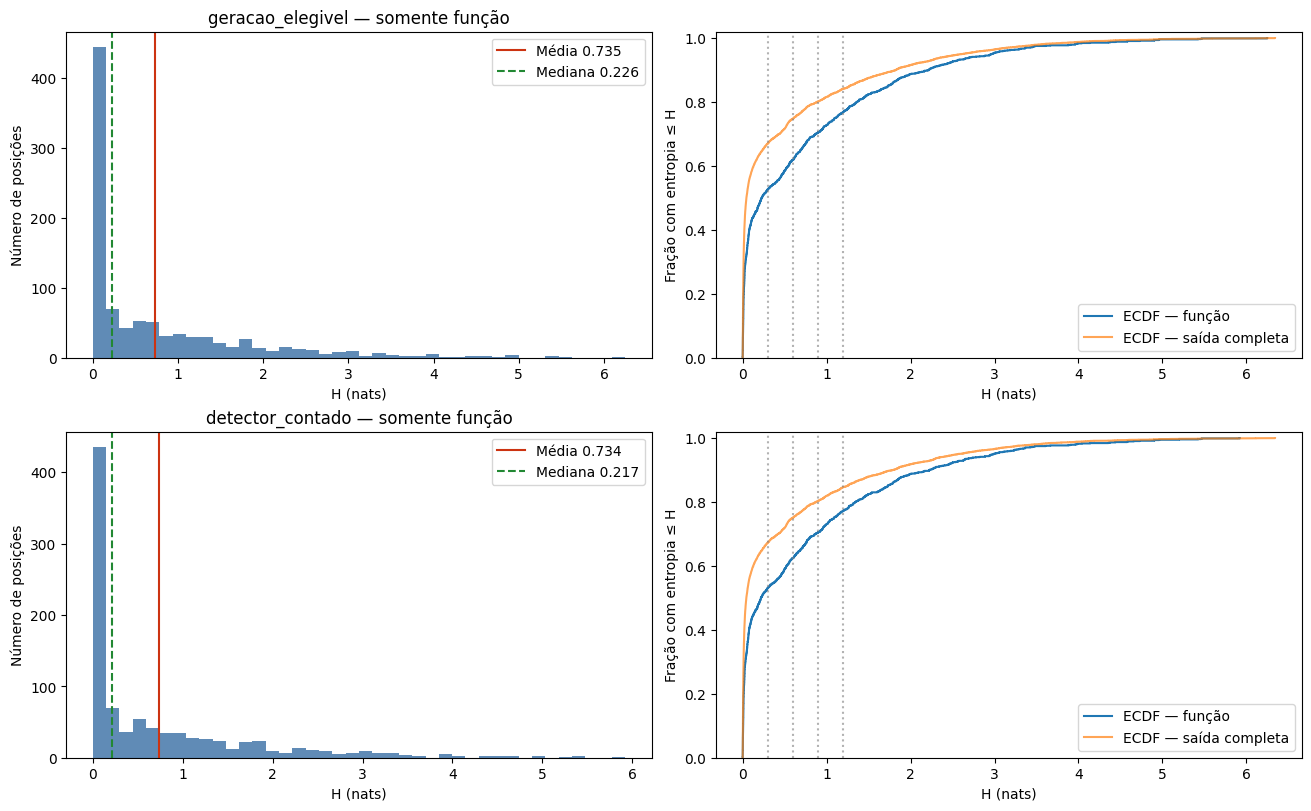

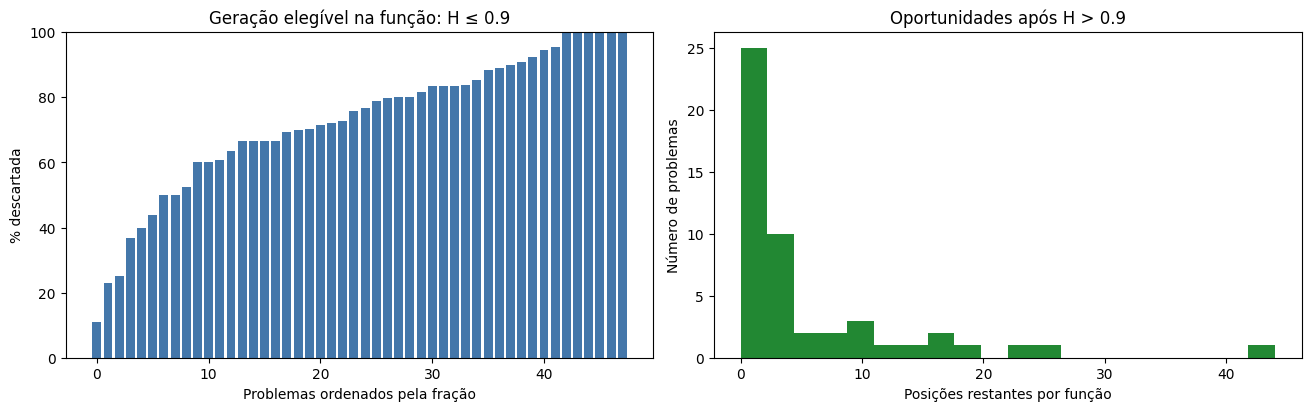

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
for row_i, population in enumerate(POPULATIONS):
    d = select_population(population, 'funcao')
    h = d.H.to_numpy()
    if len(h):
        axes[row_i,0].hist(h, bins=40, color='#4477aa', alpha=.85)
        axes[row_i,0].axvline(h.mean(), color='#cc3311', label=f'Média {h.mean():.3f}')
        axes[row_i,0].axvline(np.median(h), color='#228833', ls='--', label=f'Mediana {np.median(h):.3f}')
        axes[row_i,0].legend()
        hs = np.sort(h)
        axes[row_i,1].step(hs, np.arange(1,len(hs)+1)/len(hs), where='post', label='ECDF — função')
        full = select_population(population, 'completa').H.to_numpy()
        if len(full):
            axes[row_i,1].step(np.sort(full), np.arange(1,len(full)+1)/len(full), where='post',
                               alpha=.7, label='ECDF — saída completa')
        for tau in TAUS:
            axes[row_i,1].axvline(tau, color='gray', ls=':', alpha=.6)
        axes[row_i,1].legend()
    else:
        axes[row_i,0].text(.5,.5,'Sem posições', ha='center', transform=axes[row_i,0].transAxes)
    axes[row_i,0].set(title=population+' — somente função', xlabel='H (nats)', ylabel='Número de posições')
    axes[row_i,1].set(xlabel='H (nats)', ylabel='Fração com entropia ≤ H', ylim=(0,1.02))
fig.savefig(REPORT_DIR/'distribuicoes_entropia.png', dpi=160)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13,4), constrained_layout=True)
ordered = focus.sort_values('fracao_descartada')
axes[0].bar(np.arange(len(ordered)), ordered.fracao_descartada.to_numpy()*100, color='#4477aa')
axes[0].set(xlabel='Problemas ordenados pela fração', ylabel='% descartada', ylim=(0,100),
            title=f'Geração elegível na função: H ≤ {LIMIAR_REFERENCIA}')
axes[1].hist(focus.n_restantes, bins=min(20,max(1,len(focus))), color='#228833')
axes[1].set(xlabel='Posições restantes por função', ylabel='Número de problemas',
            title=f'Oportunidades após H > {LIMIAR_REFERENCIA}')
fig.savefig(REPORT_DIR/'distribuicao_por_problema.png', dpi=160)
plt.show()


## 12. Diagnóstico de alinhamento: decisão do gerador × token final

Uma posição pode receber viés e terminar em um token sintático; ou não receber viés e terminar
em um token contado pelo detector. A tabela quantifica esses desencontros no recorte da função.
Eles não demonstram, isoladamente, que o algoritmo está errado: o candidato e a escolha final diferem.


In [ ]:
fun = positions_df[positions_df.in_function.astype(bool)]
cross = pd.crosstab(fun.eligible, fun.counted).reindex(index=[False,True], columns=[False,True], fill_value=0)
cross.index = ['Sem viés', 'Com viés']
cross.columns = ['Token não contado', 'Token contado']
display(cross)
alignment = dict(
    n_funcao=len(fun),
    vies_mas_nao_contado=float((~fun.loc[fun.eligible,'counted'].astype(bool)).mean()) if fun.eligible.any() else None,
    sem_vies_mas_contado=float(fun.loc[~fun.eligible,'counted'].mean()) if (~fun.eligible).any() else None)
print(alignment)
cross.to_csv(REPORT_DIR/'alinhamento_gerador_detector.csv')


,Token não contado,Token contado
Sem viés,1178,53
Com viés,68,901


{'n_funcao': 2200, 'vies_mas_nao_contado': 0.07017543859649122, 'sem_vies_mas_contado': 0.04305442729488221}


## 13. Extra opcional: detecção na função

Fica desativada por padrão para manter o foco no primeiro experimento. Para ativar,
use `CALCULAR_DETECCAO=True`; numa rodada nova, também `GERAR_NEGATIVOS=True` antes de gerar.
A v3 normalmente já contém os negativos. AUROC é calculada por problema; 0,5 é o nível do acaso.

Todas as respostas marcadas continuam sendo geradas pelo STONE. Os nomes abaixo indicam
**regras de detecção**, não gerações completas dos métodos KGW/SWEET/híbrido.
Não selecionamos um limiar vencedor nesta etapa e não medimos corretude.


In [ ]:
def zscore(rows, tau=None, excl_syn=True):
    selected = [bool(row[1]) for row in rows if row[3] and not (excl_syn and row[2])
                and int(row[4]) not in tok.all_special_ids and (tau is None or row[0] > tau)]
    n = len(selected)
    return 0.0 if not n else (sum(selected)-GAMMA*n)/math.sqrt(GAMMA*(1-GAMMA)*n)

detection_df = pd.DataFrame()
if CALCULAR_DETECCAO:
    from scipy.stats import rankdata
    def auc(pos, neg):
        n1,n2 = len(pos),len(neg)
        ranks = rankdata(np.r_[pos,neg])
        return float((ranks[:n1].sum()-n1*(n1+1)/2)/(n1*n2))
    methods = {'Todos os tokens':dict(excl_syn=False),
               'Só entropia H>0.9':dict(excl_syn=False,tau=.9),
               'STONE':dict(excl_syn=True)}
    methods.update({f'STONE + H>{tau}':dict(excl_syn=True,tau=tau) for tau in TAUS})
    available = [key for key in ['un_rows','hu_rows'] if all(key in r for r in results)]
    if not available:
        print('Sem negativos em todos os problemas. Diagnóstico principal concluído; AUROC não calculada.')
    else:
        detection = []
        for key in available:
            pairs = []
            for item in normalized:
                r = item['record']
                neg = completion_rows(r,key)
                cut = cut_function(item['prompt'], [row[4] for row in neg], MAX_NEW)
                pairs.append((item['comp'][:item['cut']['keep_tokens']], neg[:cut['keep_tokens']]))
            for name, kw in methods.items():
                pos = np.array([zscore(p,**kw) for p,n in pairs])
                neg = np.array([zscore(n,**kw) for p,n in pairs])
                rng = np.random.default_rng(0)
                bs = []
                for _ in range(BOOTSTRAP_B):
                    idx = rng.integers(0,len(pairs),len(pairs))
                    bs.append(auc(pos[idx],neg[idx]))
                lo,hi = np.percentile(bs,[2.5,97.5])
                detection.append(dict(regra_detector=name, negativo=key, n=len(pairs),
                    z_marcado=pos.mean(), z_negativo=neg.mean(), AUROC=auc(pos,neg), IC_lo=lo, IC_hi=hi))
        detection_df = pd.DataFrame(detection)
        display(detection_df.round(3))
else:
    print('Detecção opcional desativada. O experimento principal não depende de AUROC.')


Detecção opcional desativada. O experimento principal não depende de AUROC.


## 14. Exportar e interpretar sem exagerar a conclusão

O relatório usa os valores desta execução, informa funções vazias/suspeitas e inclui uma análise
de sensibilidade que exclui os cortes marcados para revisão. Isso **não substitui** a revisão manual:
uma função sintaticamente válida ainda pode estar incompleta ou incorreta.

As saídas são salvas em uma pasta própria, separada do JSON original. Mudar os limiares na mesma
reanálise atualiza os CSVs/figuras dessa pasta e os parâmetros registrados, sem tocar nas amostras.


In [ ]:
tables = dict(posicoes=positions_df, resumo_entropia=summary_df, resumo_por_problema=problem_df,
    limiares_resumo=threshold_df, limiares_por_problema=threshold_problem_df, estabilidade=stability_df)
if not detection_df.empty:
    tables['deteccao_opcional'] = detection_df
for name, df in tables.items():
    df.to_csv(REPORT_DIR/f'{name}.csv', index=False)
atomic_json(REPORT_DIR/'metadados_analise.json', dict(run=run_meta, N_analisados=len(results),
    task_ids=task_ids, TAUS=TAUS, LIMIAR_REFERENCIA=LIMIAR_REFERENCIA, BOOTSTRAP_B=BOOTSTRAP_B,
    cut_rule='python_tokenize_top_level_conservative_token_boundary_v4',
    special_tokens='excluded', H_unit='nats', populations=dict(POPULATIONS)))

main = select_population('geracao_elegivel','funcao')
stats = describe_h(main.H)
low = float((main.H <= LIMIAR_REFERENCIA).mean()) if len(main) else np.nan
valid_ids = set(cuts_df.loc[~cuts_df.needs_review,'task_id'])
valid_main = main[main.task_id.isin(valid_ids)]
valid_low = float((valid_main.H <= LIMIAR_REFERENCIA).mean()) if len(valid_main) else np.nan
ref = focus
interval = stability_df[(stability_df.escopo=='funcao') &
    (stability_df.populacao=='geracao_elegivel') & (stability_df.tau==LIMIAR_REFERENCIA)].iloc[0]

report = f"""# Primeiro experimento: diagnóstico de entropia

## Pergunta e configuração
Qual é a distribuição de H antes do viés nas posições em que o STONE decide aplicar a marca?
Fonte: {'reanálise de JSON v3' if USE_LEGACY else 'rodada v4'}. Modelo: {MODEL_ID}.
Modo: {MODE}; δ={DELTA}; γ={GAMMA}; problemas analisados: {len(results)}.
Recorte principal: apenas a função; sem tokens especiais. H em nats.

## Resultado principal — geração elegível
- Posições: {stats['n']}; média de H: {stats['media']:.4f}; mediana: {stats['mediana']:.4f}.
- Fração por posições com H ≤ {LIMIAR_REFERENCIA}: {low:.1%}.
- IC bootstrap por problemas: [{interval.micro_lo:.1%}, {interval.micro_hi:.1%}].
- Média das frações por problema (peso igual às funções com posições): {interval.macro:.1%}.
- Problemas com posições elegíveis: {int(interval.problemas_validos)} de {len(results)}.
- Funções sem posições após H > {LIMIAR_REFERENCIA}: {int((ref.n_restantes==0).sum())}.
- Mediana de posições restantes por função: {ref.n_restantes.median():.1f}.

## Qualidade do recorte
- Cortes sinalizados para revisão: {int(cuts_df.needs_review.sum())} de {len(results)}.
- Excluindo esses casos: {len(valid_ids)} funções, {len(valid_main)} posições elegíveis,
  fração H ≤ {LIMIAR_REFERENCIA}: {valid_low:.1%}.
- Leia revisao_cortes.txt e auditoria_cortes.csv antes de fechar a interpretação.

## Interpretação permitida
Os valores descrevem quanto cada filtro altera a seleção nesta configuração e nestas trajetórias.
Não há um tamanho mínimo universal que torne a parcela de baixa entropia relevante: considere
a proporção removida, sua distribuição entre funções e quantas oportunidades restam.
Quando a média supera a mediana, consulte o histograma para verificar a concentração e a cauda.
Uma diferença numérica entre média e mediana, isoladamente, não prova uma forma de distribuição.

## Limites
Os primeiros N problemas não são uma amostra aleatória; uma semente não cobre a variabilidade
da geração. O bootstrap descreve estabilidade entre os problemas observados. Os cortes são
heurísticos e ast.parse só verifica sintaxe. Não se mediu pass@1 e não se gerou o híbrido.
Na v3, commits/ambiente originais não foram salvos. Modos paper e repo são interpretações
operacionais herdadas do piloto, com adaptações, não uma reprodução certificada do artigo.

## Próximo experimento
Após conferir os cortes e a estabilidade, estabilizar a referência STONE e comparar gerações
STONE, SWEET e híbrida, medindo simultaneamente detecção e corretude com protocolo fixado.
"""
(REPORT_DIR/'relatorio.md').write_text(report, encoding='utf-8')
display(Markdown(report))
print('\nArquivos exportados:')
for path in sorted(REPORT_DIR.iterdir()):
    print(path.name)


# Primeiro experimento: diagnóstico de entropia

## Pergunta e configuração
Qual é a distribuição de H antes do viés nas posições em que o STONE decide aplicar a marca?
Fonte: rodada v4. Modelo: Qwen/Qwen2.5-Coder-3B.
Modo: paper; δ=0.5; γ=0.5; problemas analisados: 50.
Recorte principal: apenas a função; sem tokens especiais. H em nats.

## Resultado principal — geração elegível
- Posições: 969; média de H: 0.7345; mediana: 0.2262.
- Fração por posições com H ≤ 0.9: 70.5%.
- IC bootstrap por problemas: [62.0%, 77.8%].
- Média das frações por problema (peso igual às funções com posições): 72.5%.
- Problemas com posições elegíveis: 48 de 50.
- Funções sem posições após H > 0.9: 8.
- Mediana de posições restantes por função: 2.5.

## Qualidade do recorte
- Cortes sinalizados para revisão: 2 de 50.
- Excluindo esses casos: 48 funções, 895 posições elegíveis,
  fração H ≤ 0.9: 69.7%.
- Leia revisao_cortes.txt e auditoria_cortes.csv antes de fechar a interpretação.

## Interpretação permitida
Os valores descrevem quanto cada filtro altera a seleção nesta configuração e nestas trajetórias.
Não há um tamanho mínimo universal que torne a parcela de baixa entropia relevante: considere
a proporção removida, sua distribuição entre funções e quantas oportunidades restam.
Quando a média supera a mediana, consulte o histograma para verificar a concentração e a cauda.
Uma diferença numérica entre média e mediana, isoladamente, não prova uma forma de distribuição.

## Limites
Os primeiros N problemas não são uma amostra aleatória; uma semente não cobre a variabilidade
da geração. O bootstrap descreve estabilidade entre os problemas observados. Os cortes são
heurísticos e ast.parse só verifica sintaxe. Não se mediu pass@1 e não se gerou o híbrido.
Na v3, commits/ambiente originais não foram salvos. Modos paper e repo são interpretações
operacionais herdadas do piloto, com adaptações, não uma reprodução certificada do artigo.

## Próximo experimento
Após conferir os cortes e a estabilidade, estabilizar a referência STONE e comparar gerações
STONE, SWEET e híbrida, medindo simultaneamente detecção e corretude com protocolo fixado.



Arquivos exportados:
alinhamento_gerador_detector.csv
auditoria_cortes.csv
distribuicao_por_problema.png
distribuicoes_entropia.png
estabilidade.csv
limiares_por_problema.csv
limiares_resumo.csv
metadados_analise.json
posicoes.csv
relatorio.md
resumo_entropia.csv
resumo_por_problema.csv
revisao_cortes.txt
